In [2]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
#passive_data = pd.read_csv('/Users/eochoa/Downloads/MPConc_WeatherMonthLocation_Passive.csv')
passive_data = pd.read_csv('evaluation_data/MPConc_WeatherMonthLocation_Passive_UPDATED.csv')
passive_data#.head()

,School,Month,Conc MP (%),Conc TWP (%),Avg temperature (F),Avg dew point (F),Avg humidity (%),Avg wind speed (mph),Avg total precipitation (in)
0,FHS,Mar,0.000000,0.001139,38.817241,31.006897,75.620690,1.451724,0.074483
1,FHS,Apr,0.000000,0.007234,51.634483,40.344828,68.241379,6.162069,0.094828
2,FHS,May,0.000000,0.004479,62.853571,53.921429,75.321429,3.253571,0.098571
3,FHS,Jun,0.013514,0.009824,68.306667,60.066667,77.233333,3.150000,0.141333
4,FHS,Jul,0.000000,0.001323,70.017857,63.867857,82.321429,2.035714,0.220000
5,FHS,Aug,0.000000,0.005136,69.837500,63.845833,83.041667,1.804167,0.106250
6,FHS,Sep,0.000000,0.003635,66.263636,60.306061,83.212121,1.836364,0.119697
7,FHS,Oct,0.000000,0.008896,60.269231,54.303846,83.076923,1.853846,0.065000
8,FHS,Nov,0.000000,0.016058,51.576667,43.386667,75.866667,4.756667,0.057667
9,FHS,Dec,0.010050,0.018330,35.534375,31.262500,84.937500,4.531250,0.035937


In [4]:
passive_data.columns

Index(['School', 'Month', 'Conc MP (%)', 'Conc TWP (%)', 'Avg temperature (F)',
       'Avg dew point (F)', 'Avg humidity (%)', 'Avg wind speed (mph)',
       'Avg total precipitation (in)'],
      dtype='object')

In [33]:
X_cat = pd.get_dummies(
    passive_data.loc[:, ['School', 'Month']],
    drop_first=True
)

X = passive_data.loc[:, ['Avg temperature (F)',
       'Avg dew point (F)', 'Avg humidity (%)', 'Avg wind speed (mph)',
       'Avg total precipitation (in)']]

X = pd.concat([X_cat, X], axis=1)
X = pd.concat([X_cat], axis=1)
X = sm.add_constant(X)  # adds intercept
#X = pd.concat([X_cat], axis=1)
y = passive_data["Conc TWP (%)"]*1000

model = sm.OLS(y, X).fit()

In [34]:
X

,const,School_FHS,School_IAO,Month_Aug,Month_Dec,Month_Jul,Month_Jun,Month_Mar,Month_May,Month_Nov,Month_Oct,Month_Sep
0,1.0,1,0,0,0,0,0,1,0,0,0,0
1,1.0,1,0,0,0,0,0,0,0,0,0,0
2,1.0,1,0,0,0,0,0,0,1,0,0,0
3,1.0,1,0,0,0,0,1,0,0,0,0,0
4,1.0,1,0,0,0,1,0,0,0,0,0,0
5,1.0,1,0,1,0,0,0,0,0,0,0,0
6,1.0,1,0,0,0,0,0,0,0,0,0,1
7,1.0,1,0,0,0,0,0,0,0,0,1,0
8,1.0,1,0,0,0,0,0,0,0,1,0,0
9,1.0,1,0,0,1,0,0,0,0,0,0,0


In [6]:
num_vars = ['Avg temperature (F)',
       'Avg dew point (F)', 'Avg humidity (%)', 'Avg wind speed (mph)',
       'Avg total precipitation (in)']
cat_vars = ['School', 'Month']

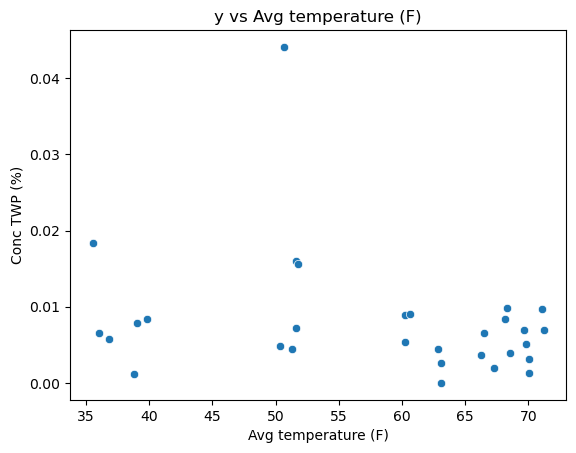

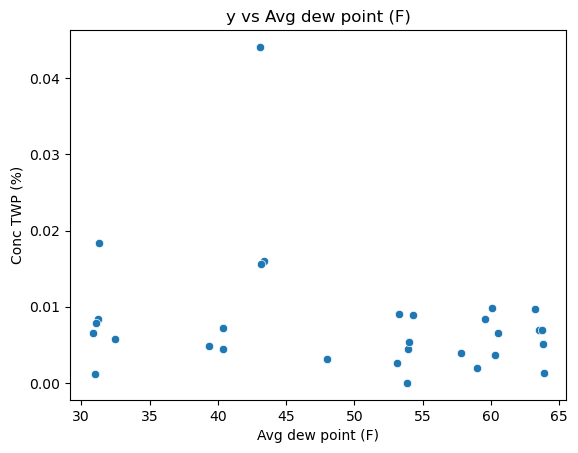

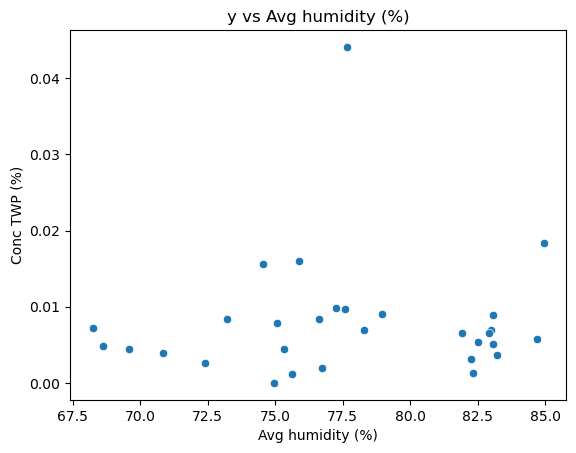

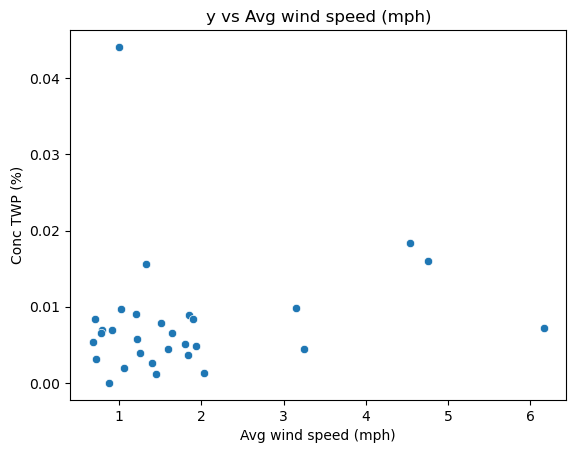

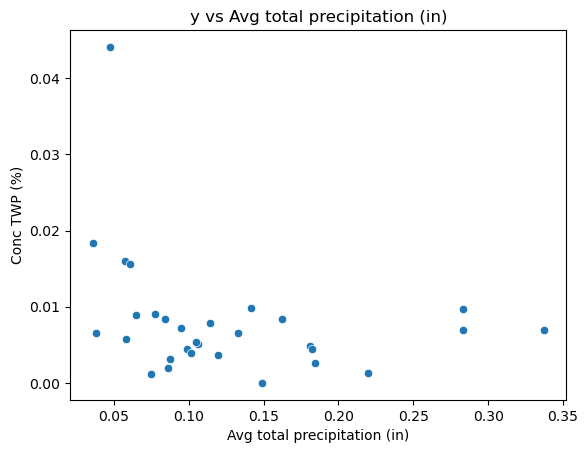

In [6]:
for col in num_vars:
    if col != 'Conc MP (%)':
        plt.figure()
        sns.scatterplot(x=passive_data[col], y=passive_data['Conc TWP (%)'])
        plt.title(f"y vs {col}")
        plt.show()

In [7]:
passive_data.groupby('School').mean()['Conc TWP (%)']

/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_11706/3743335152.py:1: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  passive_data.groupby('School').mean()['Conc TWP (%)']


School
DC     0.009263
FHS    0.007605
IAO    0.006953
Name: Conc TWP (%), dtype: float64

In [8]:
passive_data.groupby('Month').mean()['Conc TWP (%)']

/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_11706/1994534166.py:1: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  passive_data.groupby('Month').mean()['Conc TWP (%)']


Month
Apr    0.005539
Aug    0.005071
Dec    0.010205
Jul    0.005982
Jun    0.007387
Mar    0.005803
May    0.002348
Nov    0.025247
Oct    0.007775
Sep    0.004046
Name: Conc TWP (%), dtype: float64

In [9]:
passive_data.groupby('Month').mean()#['Conc TWP (%)']

/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_11706/2297513190.py:1: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  passive_data.groupby('Month').mean()#['Conc TWP (%)']


,Conc MP (%),Conc TWP (%),Avg temperature (F),Avg dew point (F),Avg humidity (%),Avg wind speed (mph),Avg total precipitation (in)
Month,,,,,,,
Apr,0.000000,0.005539,51.083295,40.038161,68.809579,3.228812,0.152843
Aug,0.001642,0.005071,70.362389,58.469602,81.190556,1.144278,0.159085
Dec,0.005059,0.010205,36.119581,31.538688,83.842385,2.468463,0.044071
Jul,0.001684,0.005982,70.255911,63.625534,80.969212,1.286617,0.280197
Jun,0.007577,0.007387,68.345952,59.162698,74.907937,1.701111,0.134921
Mar,0.001709,0.005803,39.224631,31.090312,74.633005,1.622003,0.090969
May,0.001684,0.002348,63.001111,53.643333,74.228571,1.845238,0.143944
Nov,0.001692,0.025247,51.320421,43.219617,76.028352,2.362529,0.055341
Oct,0.003724,0.007775,60.382847,53.873696,81.508400,1.247834,0.082471


In [9]:
np.corrcoef(np.array(X).T)

/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/numpy/lib/function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/numpy/lib/function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


array([[ 1.00000000e+00, -5.00000000e-01, -9.81307787e-18,
         2.61682076e-17, -9.81307787e-18, -9.81307787e-18,
         3.27102596e-18, -1.63551298e-17,  1.47196168e-17,
         3.27102596e-18, -3.27102596e-18,             nan,
        -9.65817400e-03,  4.66852443e-02,  1.72464634e-01,
         6.95980077e-01, -2.30167730e-01],
       [-5.00000000e-01,  1.00000000e+00, -3.27102596e-18,
         2.61682076e-17, -3.27102596e-18, -3.27102596e-18,
         1.63551298e-17, -9.81307787e-18,  1.47196168e-17,
         9.81307787e-18,  3.27102596e-18,             nan,
         1.76876103e-02,  3.70293567e-04, -3.50909746e-01,
        -2.44946600e-01,  1.16458665e-01],
       [-9.81307787e-18, -3.27102596e-18,  1.00000000e+00,
        -1.11111111e-01, -1.11111111e-01, -1.11111111e-01,
        -1.11111111e-01, -1.11111111e-01, -1.11111111e-01,
        -1.11111111e-01, -1.11111111e-01,             nan,
         3.52388291e-01,  2.56961712e-01,  2.39978021e-01,
        -1.72883443e-01,  1.4

<AxesSubplot: >

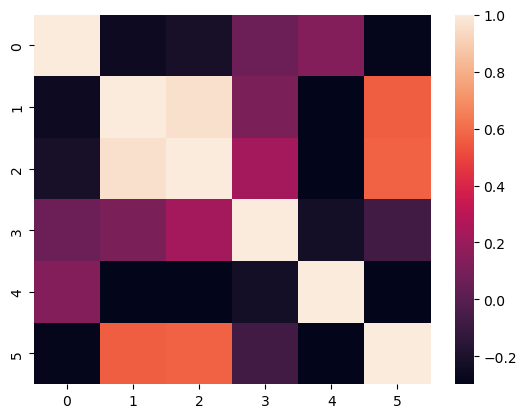

In [10]:
X = passive_data.loc[:, ['Conc TWP (%)', 'Avg temperature (F)',
       'Avg dew point (F)', 'Avg humidity (%)', 'Avg wind speed (mph)',
       'Avg total precipitation (in)']]
sns.heatmap(np.corrcoef(np.array(X).T))

(array([ 8., 14.,  4.,  2.,  1.,  0.,  0.,  0.,  0.,  1.]),
 array([ 0.       ,  4.4106035,  8.821207 , 13.2318105, 17.642414 ,
        22.0530175, 26.463621 , 30.8742245, 35.284828 , 39.6954315,
        44.106035 ]),
 <BarContainer object of 10 artists>)

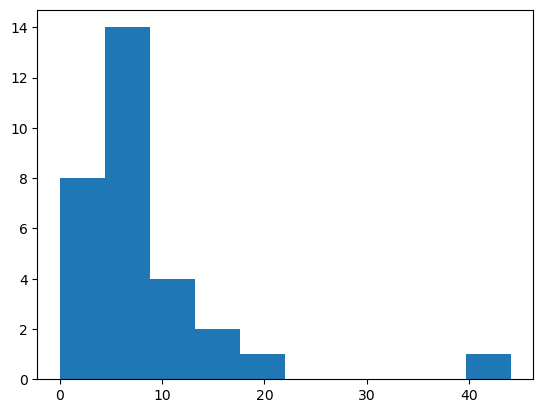

In [11]:
plt.hist(y)

In [12]:
f_test = model.f_test("School_FHS = 0, School_IAO = 0")
f_test

<class 'statsmodels.stats.contrast.ContrastResults'>
<F test: F=0.965845834426038, p=0.40637146334411783, df_denom=13, df_num=2>

In [13]:
f_test = model.f_test('Month_Aug=0, Month_Dec=0, Month_Jul=0, Month_Jun=0, Month_Mar=0, Month_May=0, Month_Nov=0, Month_Oct=0, Month_Sep=0')
f_test

<class 'statsmodels.stats.contrast.ContrastResults'>
<F test: F=2.231798549931593, p=0.09153939285263078, df_denom=13, df_num=9>

In [26]:
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           Conc TWP (%)   R-squared:                       0.116
Model:                            OLS   Adj. R-squared:                 -0.069
Method:                 Least Squares   F-statistic:                    0.6268
Date:                Thu, 23 Apr 2026   Prob (F-statistic):              0.681
Time:                        14:13:33   Log-Likelihood:                -102.83
No. Observations:                  30   AIC:                             217.7
Df Residuals:                      24   BIC:                             226.1
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
const           

In [35]:
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           Conc TWP (%)   R-squared:                       0.610
Model:                            OLS   Adj. R-squared:                  0.372
Method:                 Least Squares   F-statistic:                     2.561
Date:                Mon, 15 Jun 2026   Prob (F-statistic):             0.0371
Time:                        17:15:56   Log-Likelihood:                -90.542
No. Observations:                  30   AIC:                             205.1
Df Residuals:                      18   BIC:                             221.9
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          6.8618      4.041      1.698      0.1

In [10]:
results = pd.DataFrame({
    "coef": model.params,
    "std_err": model.bse,
    "t_stat": model.tvalues,
    "p_value": model.pvalues
})

print(results)


                 coef   std_err    t_stat   p_value
School_FHS   0.057810  2.802018  0.020631  0.983755
School_IAO  -0.594672  2.802018 -0.212230  0.834188
Month_Aug    5.249936  4.177002  1.256867  0.224034
Month_Dec   10.383540  4.177002  2.485883  0.022396
Month_Jul    6.160901  4.177002  1.474958  0.156603
Month_Jun    7.566167  4.177002  1.811387  0.085920
Month_Mar    5.981758  4.177002  1.432070  0.168371
Month_May    2.527145  4.177002  0.605014  0.552328
Month_Nov   25.425522  4.177002  6.087027  0.000007
Month_Oct    7.954390  4.177002  1.904330  0.072122
Month_Sep    4.225012  4.177002  1.011494  0.324489


In [36]:
results = pd.DataFrame({
    "coef": model.params,
    "std_err": model.bse,
    "t_stat": model.tvalues,
    "p_value": model.pvalues
})

print(results)


                 coef   std_err    t_stat   p_value
const        6.861813  4.040672  1.698186  0.106692
School_FHS  -1.657644  2.857186 -0.580166  0.568995
School_IAO  -2.310126  2.857186 -0.808532  0.429342
Month_Aug   -0.468242  5.216485 -0.089762  0.929468
Month_Dec    4.665362  5.216485  0.894350  0.382938
Month_Jul    0.442723  5.216485  0.084870  0.933302
Month_Jun    1.847990  5.216485  0.354260  0.727260
Month_Mar    0.263580  5.216485  0.050528  0.960258
Month_May   -3.191033  5.216485 -0.611721  0.548372
Month_Nov   19.707344  5.216485  3.777897  0.001378
Month_Oct    2.236212  5.216485  0.428682  0.673241
Month_Sep   -1.493166  5.216485 -0.286240  0.777963


In [15]:
results = pd.DataFrame({
    "coef": model.params,
    "std_err": model.bse,
    "t_stat": model.tvalues,
    "p_value": model.pvalues
})

print(results)


                                    coef     std_err    t_stat   p_value
School_FHS                     -8.875085    6.436361 -1.378898  0.191190
School_IAO                     -0.558364    6.495714 -0.085959  0.932809
Month_Aug                      88.407180   96.811264  0.913191  0.377767
Month_Dec                     -70.014408   52.270444 -1.339465  0.203367
Month_Jul                      86.653638   94.700111  0.915032  0.376835
Month_Jun                      79.947914   80.367190  0.994783  0.337998
Month_Mar                     -52.746312   43.883329 -1.201967  0.250815
Month_May                      51.051476   57.181907  0.892791  0.388197
Month_Nov                      17.902491   17.073021  1.048584  0.313474
Month_Oct                      41.687932   57.649808  0.723124  0.482413
Month_Sep                      66.721895   81.650638  0.817163  0.428557
const                         217.788034  308.384562  0.706222  0.492513
Avg temperature (F)            -5.116034    4.29081

In [19]:
model.params

const          6.861813
School_FHS    -1.657644
School_IAO    -2.310126
Month_Aug     -0.468242
Month_Dec      4.665362
Month_Jul      0.442723
Month_Jun      1.847990
Month_Mar      0.263580
Month_May     -3.191033
Month_Nov     19.707344
Month_Oct      2.236212
Month_Sep     -1.493166
dtype: float64

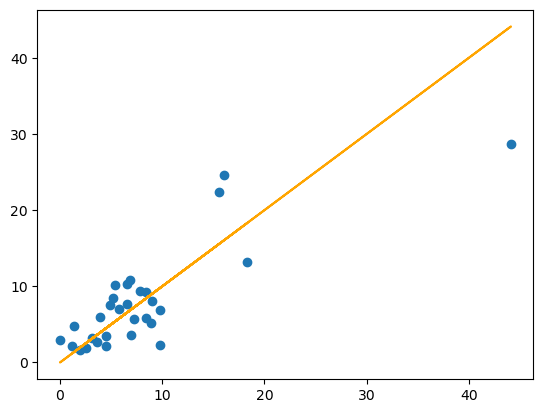

In [27]:
plt.scatter(
    y,    
    model.predict(X)
)
plt.plot(
    y,    
    y,
    c='orange'
)